In [1]:
import polars as pl
e= pl.read_parquet("enappsys_data.parquet")
e= e.select(pl.col("delivery_start").dt.convert_time_zone("UTC"), pl.col("residual_load_entsoe_fcs").alias("entsoe"),pl.col("residual_load_fcs").alias("enappsys"))
print(e)

shape: (23_324, 3)
┌─────────────────────────┬─────────┬──────────┐
│ delivery_start          ┆ entsoe  ┆ enappsys │
│ ---                     ┆ ---     ┆ ---      │
│ datetime[μs, UTC]       ┆ f64     ┆ f64      │
╞═════════════════════════╪═════════╪══════════╡
│ 2025-12-31 23:00:00 UTC ┆ 12073.0 ┆ 17594.0  │
│ 2025-12-31 23:15:00 UTC ┆ 10821.0 ┆ 16404.0  │
│ 2025-12-31 23:30:00 UTC ┆ 10246.0 ┆ 15619.0  │
│ 2025-12-31 23:45:00 UTC ┆ 9326.0  ┆ 14055.0  │
│ 2026-01-01 00:00:00 UTC ┆ 8469.0  ┆ 10310.0  │
│ …                       ┆ …       ┆ …        │
│ 2026-08-31 20:45:00 UTC ┆ null    ┆ 18895.0  │
│ 2026-08-31 21:00:00 UTC ┆ null    ┆ 18243.0  │
│ 2026-08-31 21:15:00 UTC ┆ null    ┆ 17943.0  │
│ 2026-08-31 21:30:00 UTC ┆ null    ┆ 17379.0  │
│ 2026-08-31 21:45:00 UTC ┆ null    ┆ 17144.0  │
└─────────────────────────┴─────────┴──────────┘


In [2]:
ew = pl.read_parquet("energy_weather_data.parquet")
ew = ew.select(pl.col("delivery_start").dt.convert_time_zone("UTC"), pl.col("residual_load_fcs").alias("energy_weather"))

print(ew)




shape: (17_188, 2)
┌─────────────────────────┬────────────────┐
│ delivery_start          ┆ energy_weather │
│ ---                     ┆ ---            │
│ datetime[μs, UTC]       ┆ f64            │
╞═════════════════════════╪════════════════╡
│ 2026-02-06 23:00:00 UTC ┆ 39307.856365   │
│ 2026-02-06 23:15:00 UTC ┆ 38762.372586   │
│ 2026-02-06 23:30:00 UTC ┆ 38222.147659   │
│ 2026-02-06 23:45:00 UTC ┆ 37736.53953    │
│ 2026-02-07 00:00:00 UTC ┆ 36742.668225   │
│ …                       ┆ …              │
│ 2026-08-30 22:45:00 UTC ┆ 32908.03524    │
│ 2026-08-30 23:00:00 UTC ┆ 32399.600856   │
│ 2026-08-30 23:15:00 UTC ┆ 31996.278984   │
│ 2026-08-30 23:30:00 UTC ┆ 31813.819872   │
│ 2026-08-30 23:45:00 UTC ┆ 31769.422724   │
└─────────────────────────┴────────────────┘


In [3]:
k = pl.read_parquet("kpler_data.parquet")


In [4]:
result= (
    e
    .join(ew, on="delivery_start", how="outer")
    .join(k, left_on="delivery_start",right_on="time", how="outer")
)


print(result)

shape: (25_636, 13)
┌─────────────┬─────────┬──────────┬─────────────┬───┬─────────┬──────────┬──────────┬─────────────┐
│ delivery_st ┆ entsoe  ┆ enappsys ┆ delivery_st ┆ … ┆ GFS_OP  ┆ EC_AIFS  ┆ EC_ENS   ┆ EC_AIFS_ENS │
│ art         ┆ ---     ┆ ---      ┆ art_right   ┆   ┆ ---     ┆ ---      ┆ ---      ┆ ---         │
│ ---         ┆ f64     ┆ f64      ┆ ---         ┆   ┆ f64     ┆ f64      ┆ f64      ┆ f64         │
│ datetime[μs ┆         ┆          ┆ datetime[μs ┆   ┆         ┆          ┆          ┆             │
│ , UTC]      ┆         ┆          ┆ , UTC]      ┆   ┆         ┆          ┆          ┆             │
╞═════════════╪═════════╪══════════╪═════════════╪═══╪═════════╪══════════╪══════════╪═════════════╡
│ 2026-01-01  ┆ 8469.0  ┆ 10310.0  ┆ null        ┆ … ┆ 3739.45 ┆ 8379.26  ┆ 7036.98  ┆ null        │
│ 00:00:00    ┆         ┆          ┆             ┆   ┆         ┆          ┆          ┆             │
│ UTC         ┆         ┆          ┆             ┆   ┆         ┆       

C:\Users\HanhTa\AppData\Local\Temp\ipykernel_14352\3052157690.py:3: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  .join(ew, on="delivery_start", how="outer")
C:\Users\HanhTa\AppData\Local\Temp\ipykernel_14352\3052157690.py:4: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  .join(k, left_on="delivery_start",right_on="time", how="outer")


In [5]:
result = (
    result
    .with_columns(
        pl.coalesce(
            [
                pl.col("delivery_start"),
                pl.col("delivery_start_right"),
                pl.col("time"),
            ]
        ).alias("delivery_start")
    )
    .drop([
        "delivery_start_right",
        "time",
    ])
    .sort("delivery_start")
)
print(result)

shape: (25_636, 11)
┌─────────────┬─────────┬──────────┬─────────────┬───┬──────────┬──────────┬──────────┬────────────┐
│ delivery_st ┆ entsoe  ┆ enappsys ┆ energy_weat ┆ … ┆ GFS_OP   ┆ EC_AIFS  ┆ EC_ENS   ┆ EC_AIFS_EN │
│ art         ┆ ---     ┆ ---      ┆ her         ┆   ┆ ---      ┆ ---      ┆ ---      ┆ S          │
│ ---         ┆ f64     ┆ f64      ┆ ---         ┆   ┆ f64      ┆ f64      ┆ f64      ┆ ---        │
│ datetime[μs ┆         ┆          ┆ f64         ┆   ┆          ┆          ┆          ┆ f64        │
│ , UTC]      ┆         ┆          ┆             ┆   ┆          ┆          ┆          ┆            │
╞═════════════╪═════════╪══════════╪═════════════╪═══╪══════════╪══════════╪══════════╪════════════╡
│ 2025-12-31  ┆ 12073.0 ┆ 17594.0  ┆ null        ┆ … ┆ null     ┆ null     ┆ null     ┆ null       │
│ 23:00:00    ┆         ┆          ┆             ┆   ┆          ┆          ┆          ┆            │
│ UTC         ┆         ┆          ┆             ┆   ┆          ┆      

In [6]:
result = result.filter(
    (pl.col("delivery_start") >= pl.datetime(2026, 1, 1)) &
    (pl.col("delivery_start") < pl.datetime(2026, 9, 1))
)

print(result)

SchemaError: could not evaluate '>=' comparison between series 'delivery_start' of dtype: Datetime('μs', 'UTC') and series 'literal' of dtype: Datetime('μs')

This error occurred in the following expression:
	[(col("delivery_start")) >= (2026-01-01 00:00:00)]
while evaluating this larger expression:
	[([(col("delivery_start")) >= (2026-01-01 00:00:00)]) & ([(col("delivery_start")) < (2026-09-01 00:00:00)])]


In [ ]:
result.write_parquet("result.complete")

In [ ]:
#1: bias matrix : Bias (A,B) = mean(A-B) ; who is systematically above or below whom? (systematic overestimation/ underestimation), value close to 0 means no systematic errors.
# dictionary row becomes a row in dataframe
import polars as pl

forecasts = ["entsoe","enappsys","energy_weather","EC_AIFS_ENS"]

rows = []

for a in forecasts:
    row = {"forecast": a}

    for b in forecasts:
        if a == b:
            row[b] = 0.0
        else:
            row[b] = (result[a] - result[b]).mean()

    rows.append(row)

bias_matrix = pl.DataFrame(rows)

print(bias_matrix)

shape: (4, 5)
┌────────────────┬────────────┬─────────────┬────────────────┬─────────────┐
│ forecast       ┆ entsoe     ┆ enappsys    ┆ energy_weather ┆ EC_AIFS_ENS │
│ ---            ┆ ---        ┆ ---         ┆ ---            ┆ ---         │
│ str            ┆ f64        ┆ f64         ┆ f64            ┆ f64         │
╞════════════════╪════════════╪═════════════╪════════════════╪═════════════╡
│ entsoe         ┆ 0.0        ┆ -186.912703 ┆ -3007.86191    ┆ -621.805392 │
│ enappsys       ┆ 186.912703 ┆ 0.0         ┆ -3337.486106   ┆ -845.081648 │
│ energy_weather ┆ 3007.86191 ┆ 3337.486106 ┆ 0.0            ┆ 2087.027327 │
│ EC_AIFS_ENS    ┆ 621.805392 ┆ 845.081648  ┆ -2087.027327   ┆ 0.0         │
└────────────────┴────────────┴─────────────┴────────────────┴─────────────┘


In [ ]:
import polars as pl
forecasts= result.columns[2:]
row = []
for a in forecasts:
    row = {"forecast":a}
    for b in forecasts:
        if a == b:
           row[b]= 0.0
        else:
           row[b]=round((result[a]-result[b]).mean(),2)

    rows.append(row)
bias_matrix = pl.DataFrame(rows)
print(bias_matrix)



shape: (13, 11)
┌────────────┬────────────┬────────────┬────────────┬───┬──────────┬─────────┬──────────┬──────────┐
│ forecast   ┆ entsoe     ┆ enappsys   ┆ energy_wea ┆ … ┆ EC_46    ┆ GFS_OP  ┆ EC_AIFS  ┆ EC_ENS   │
│ ---        ┆ ---        ┆ ---        ┆ ther       ┆   ┆ ---      ┆ ---     ┆ ---      ┆ ---      │
│ str        ┆ f64        ┆ f64        ┆ ---        ┆   ┆ f64      ┆ f64     ┆ f64      ┆ f64      │
│            ┆            ┆            ┆ f64        ┆   ┆          ┆         ┆          ┆          │
╞════════════╪════════════╪════════════╪════════════╪═══╪══════════╪═════════╪══════════╪══════════╡
│ entsoe     ┆ 0.0        ┆ -186.91270 ┆ -3007.8619 ┆ … ┆ null     ┆ null    ┆ null     ┆ null     │
│            ┆            ┆ 3          ┆ 1          ┆   ┆          ┆         ┆          ┆          │
│ enappsys   ┆ 186.912703 ┆ 0.0        ┆ -3337.4861 ┆ … ┆ null     ┆ null    ┆ null     ┆ null     │
│            ┆            ┆            ┆ 06         ┆   ┆          ┆       

In [ ]:
result.write_parquet("forecast_result.parquet")


In [ ]:
import os
print(os.environ.get("MPLBACKEND"))


module://matplotlib_inline.backend_inline


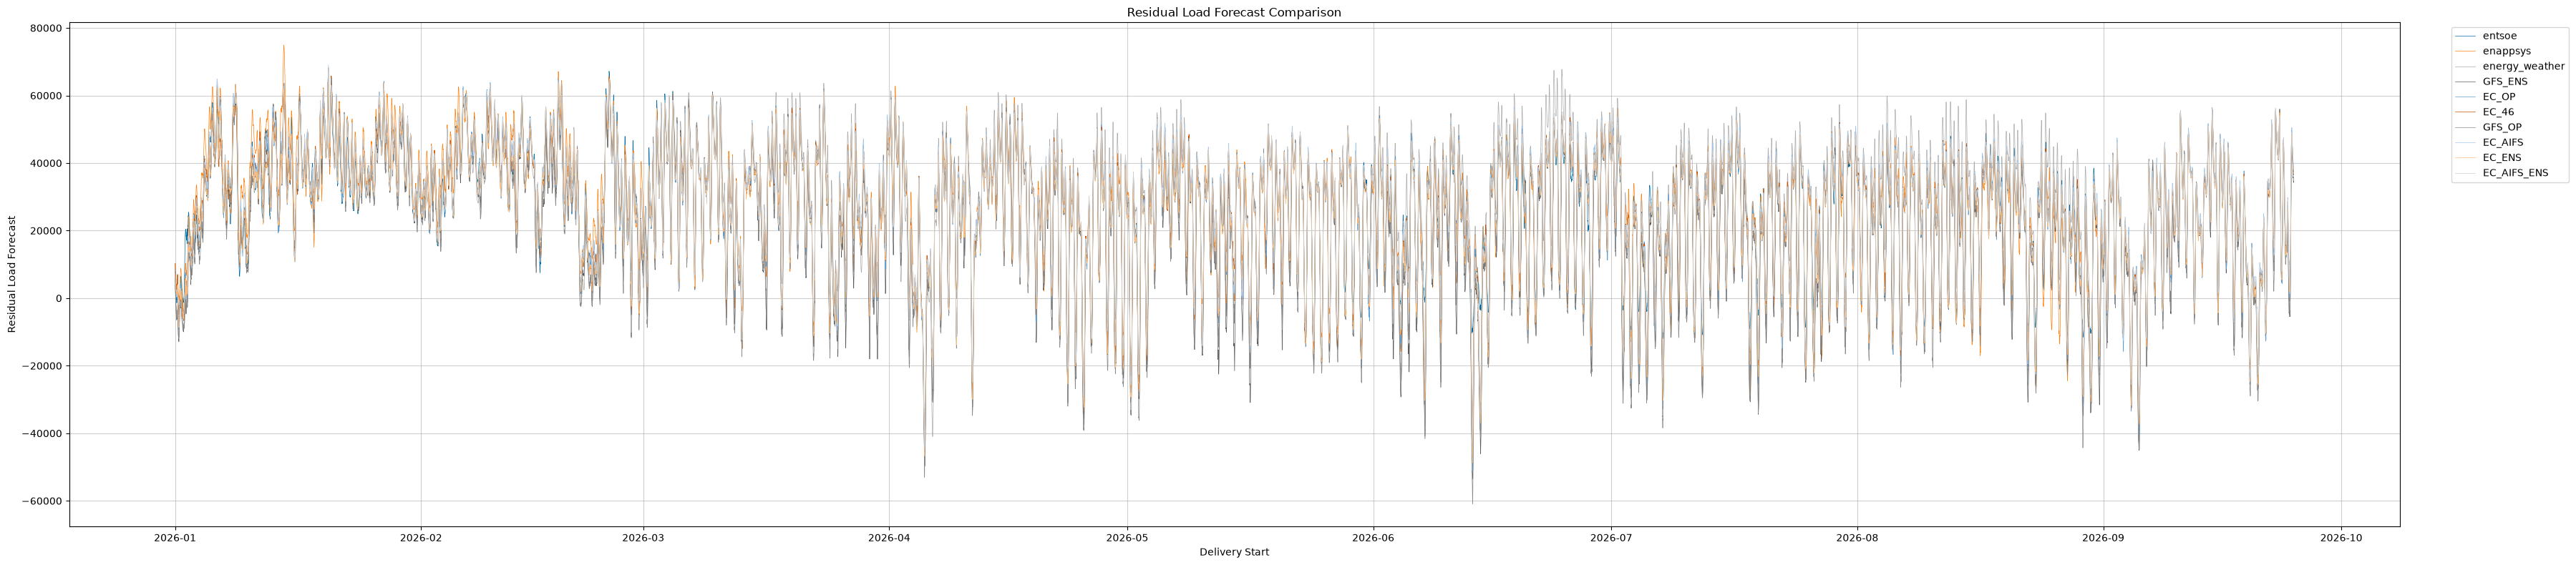

In [ ]:
import matplotlib.pyplot as plt
plt.style.use("tableau-colorblind10")
import numpy as np
plt.figure(figsize =(36, 8))
for cols in result.columns[1:]:
    plt.plot(
        result["delivery_start"],
        result[cols],linewidth=0.5,
        label=cols
    )
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha= 0.6)
plt.xlabel("Delivery Start")
plt.ylabel("Residual Load Forecast")
plt.title("Residual Load Forecast Comparison")
plt.tight_layout()

plt.show()


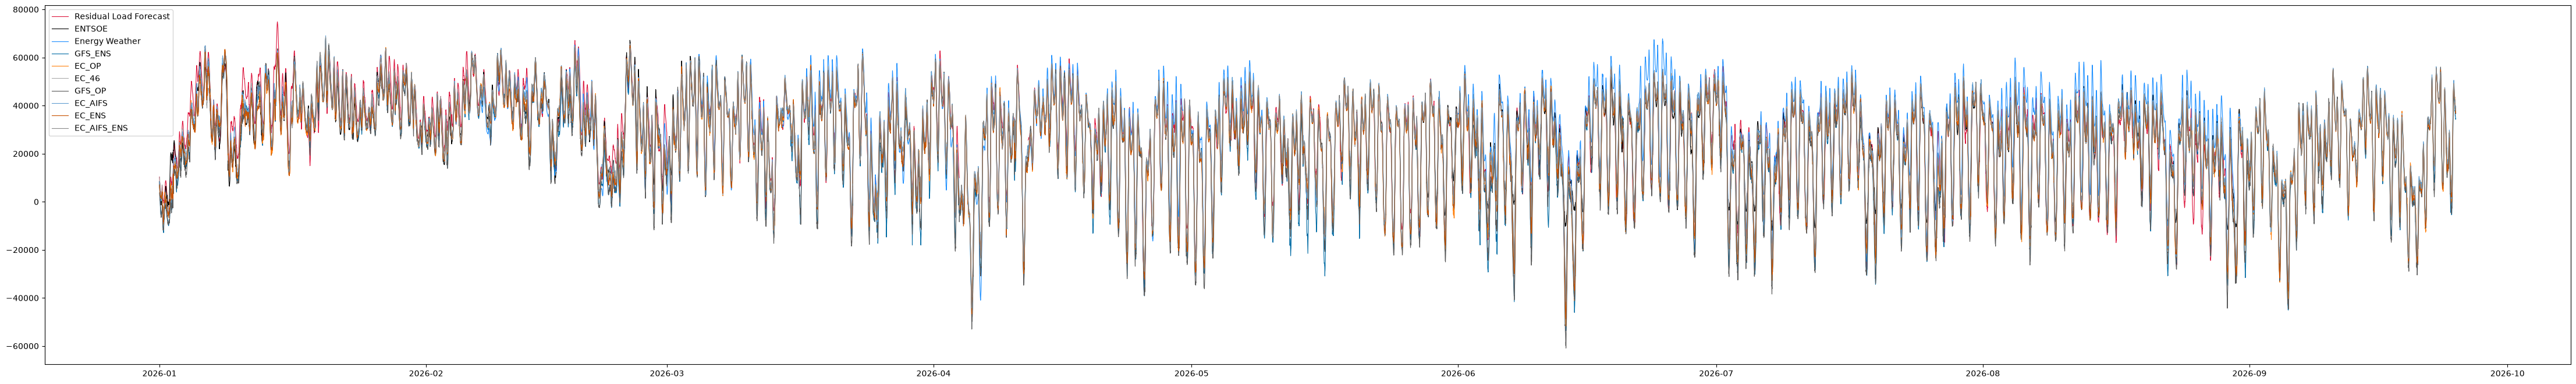

In [ ]:
plt.figure(figsize=(56,8))

#main series
plt.plot(
    result["delivery_start"],
    result["enappsys"],
    color="crimson",
    linewidth=0.8,
    label="Residual Load Forecast"

)


plt.plot(
    result["delivery_start"],
    result["entsoe"],
    color="black",
    linewidth= 0.8,
    label="ENTSOE"
)

plt.plot(
    result["delivery_start"],
    result["energy_weather"],
    color="dodgerblue",
    linewidth=0.8,
    label="Energy Weather"

)

for cols in result.columns[4:]:
  plt.plot(
     result["delivery_start"],result[cols],
     linewidth=0.8,
     label=cols,
     
)

plt.legend()
plt.show()

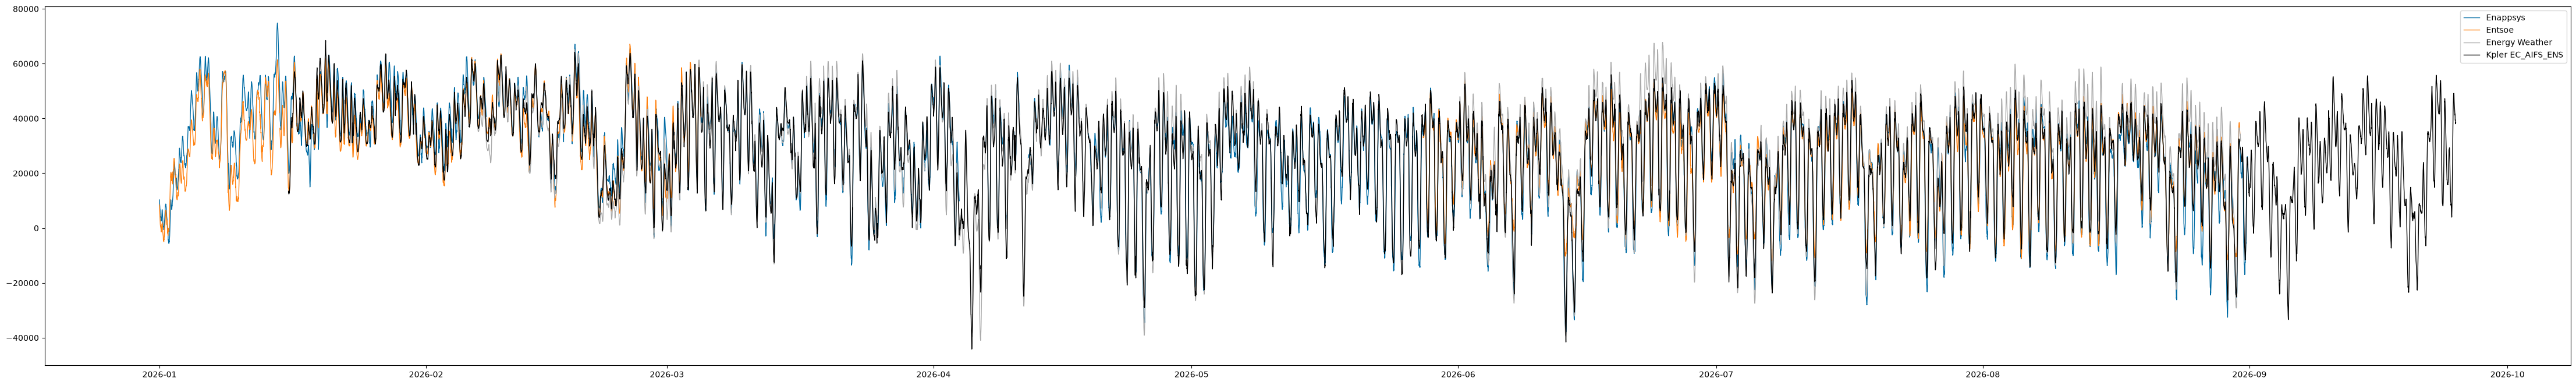

In [ ]:
plt.figure(figsize=(56,8))

#main series
plt.plot(
    result["delivery_start"],
    result["enappsys"],

    linewidth=1,
    label="Enappsys"

)


plt.plot(
    result["delivery_start"],
    result["entsoe"],
    linewidth= 1,
    label="Entsoe"
)

plt.plot(
    result["delivery_start"],
    result["energy_weather"],

    linewidth=1,
    label="Energy Weather" )

plt.plot(
    result["delivery_start"],
    result["EC_AIFS_ENS"],
    color = "black",

    linewidth =1,
    label= "Kpler EC_AIFS_ENS"


)
plt.legend()
plt.show()



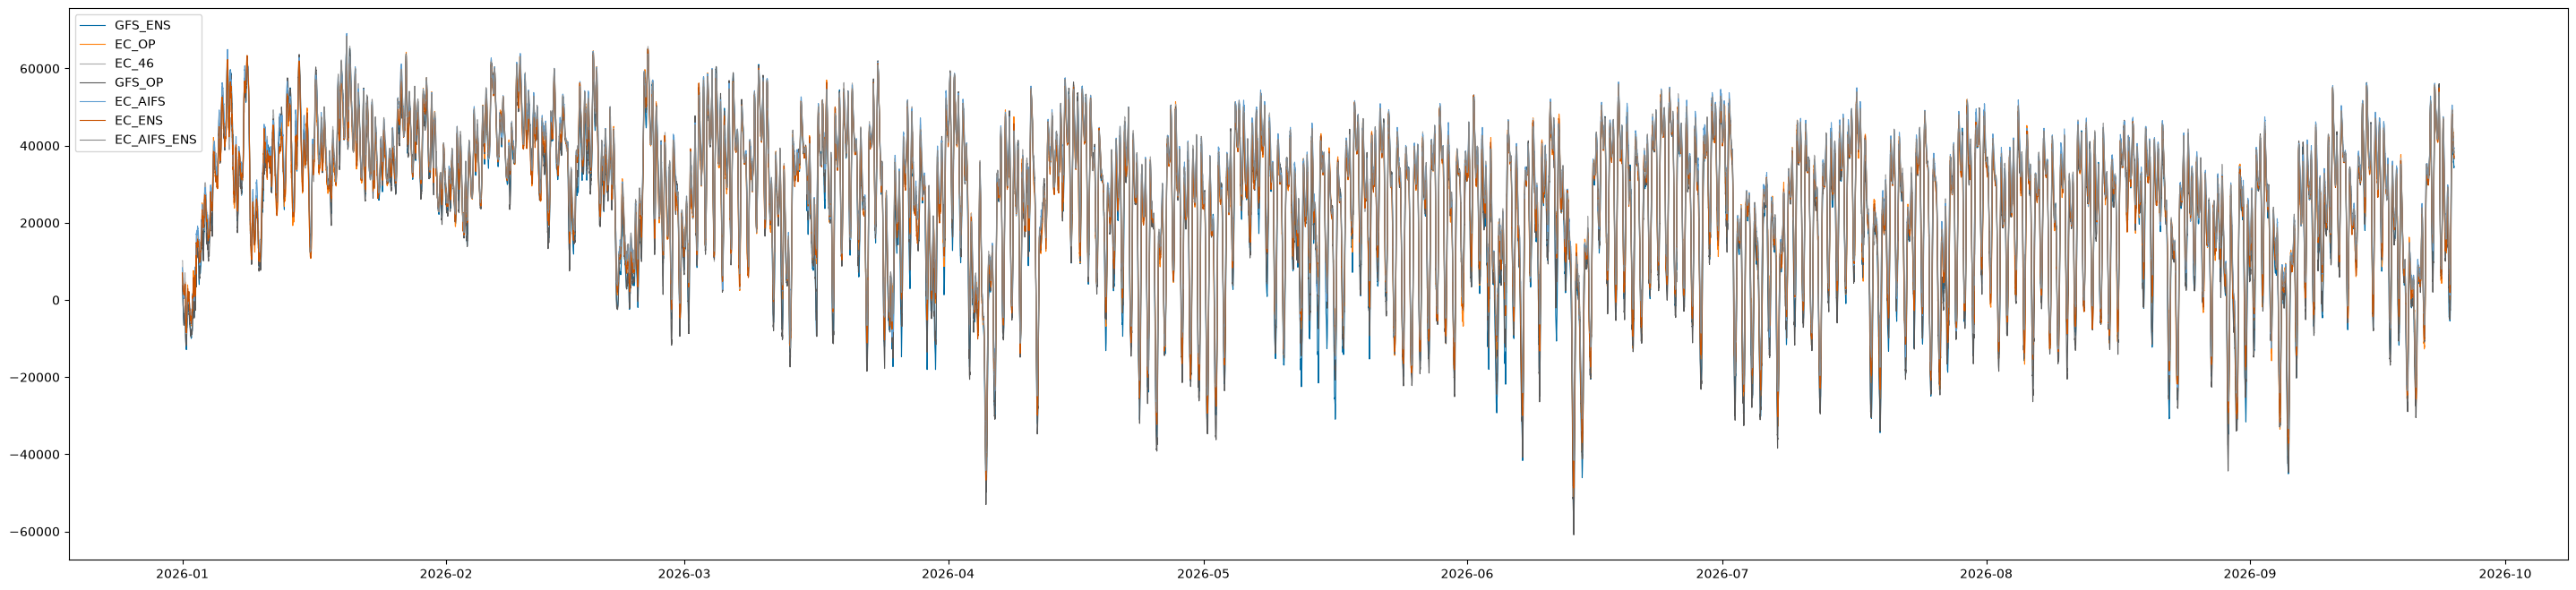

In [ ]:
plt.figure(figsize=(36,8))
for cols in result.columns[4:11]:
  plt.plot(
     result["delivery_start"],result[cols],
     linewidth=0.8,
     label=cols,
     
)

plt.legend()
plt.show()

In [ ]:
# Mean Bias Error (+/-)
forecasts = ["enappsys","entsoe","energy_weather","EC_AIFS_ENS"]
import polars as pl

rows = []

for a in forecasts:
    row = {}
    for b in forecasts:
        if a == b:
            row[b] = 0.0
        else:
            row[b] = (
                result.select((pl.col(a) - pl.col(b)).mean().round(2))
                .item()
            )
    rows.append(row)

bias_matrix = pl.DataFrame(rows).with_columns(
    forecast=pl.Series(forecasts)
).select(["forecast"] + forecasts)

print(bias_matrix)

shape: (4, 5)
┌────────────────┬──────────┬─────────┬────────────────┬─────────────┐
│ forecast       ┆ enappsys ┆ entsoe  ┆ energy_weather ┆ EC_AIFS_ENS │
│ ---            ┆ ---      ┆ ---     ┆ ---            ┆ ---         │
│ str            ┆ f64      ┆ f64     ┆ f64            ┆ f64         │
╞════════════════╪══════════╪═════════╪════════════════╪═════════════╡
│ enappsys       ┆ 0.0      ┆ 186.91  ┆ -3337.49       ┆ -845.08     │
│ entsoe         ┆ -186.91  ┆ 0.0     ┆ -3007.86       ┆ -621.81     │
│ energy_weather ┆ 3337.49  ┆ 3007.86 ┆ 0.0            ┆ 2087.03     │
│ EC_AIFS_ENS    ┆ 845.08   ┆ 621.81  ┆ -2087.03       ┆ 0.0         │
└────────────────┴──────────┴─────────┴────────────────┴─────────────┘


In [ ]:
# Absolute MBE############
import pandas as pd
forecast = ["entsoe","enappsys","energy_weather","EC_AIFS_ENS"]


rows = []

for a in forecasts:
    row = {}
    for b in forecasts:
        if a == b:
            row[b] = 0.0
        else:
            row[b] = (
                result.select(abs(pl.col(a) - pl.col(b))).mean()).item()
    rows.append(row)

bias_matrix = pl.DataFrame(rows).with_columns(
    forecast=pl.Series(forecasts)
).select(["forecast"] + forecasts)

print(bias_matrix)


shape: (4, 5)
┌────────────────┬─────────────┬─────────────┬────────────────┬─────────────┐
│ forecast       ┆ enappsys    ┆ entsoe      ┆ energy_weather ┆ EC_AIFS_ENS │
│ ---            ┆ ---         ┆ ---         ┆ ---            ┆ ---         │
│ str            ┆ f64         ┆ f64         ┆ f64            ┆ f64         │
╞════════════════╪═════════════╪═════════════╪════════════════╪═════════════╡
│ enappsys       ┆ 0.0         ┆ 4584.396891 ┆ 5361.476417    ┆ 3593.425629 │
│ entsoe         ┆ 4584.396891 ┆ 0.0         ┆ 6226.466464    ┆ 2832.975183 │
│ energy_weather ┆ 5361.476417 ┆ 6226.466464 ┆ 0.0            ┆ 4633.412813 │
│ EC_AIFS_ENS    ┆ 3593.425629 ┆ 2832.975183 ┆ 4633.412813    ┆ 0.0         │
└────────────────┴─────────────┴─────────────┴────────────────┴─────────────┘


In [ ]:
# Difference-overtime-plots
descibe = result.describe()

In [ ]:
# ~pl.col : NOT
stats =descibe.select("statistic","entsoe","enappsys","energy_weather", "EC_AIFS_ENS").filter(~pl.col("statistic").is_in(["count","null_count","25%","75%"]))


In [ ]:
# there is a string column : statistic => unable to round whole dataframe => select numeric columns, or use pl.col(pl.NUMERIC_DTYPES).round(2)--- doesnt work here
stats =stats.with_columns(pl.col("enappsys","entsoe","energy_weather","EC_AIFS_ENS").round(2))
print (stats)

shape: (5, 5)
┌───────────┬──────────┬──────────┬────────────────┬─────────────┐
│ statistic ┆ entsoe   ┆ enappsys ┆ energy_weather ┆ EC_AIFS_ENS │
│ ---       ┆ ---      ┆ ---      ┆ ---            ┆ ---         │
│ str       ┆ f64      ┆ f64      ┆ f64            ┆ f64         │
╞═══════════╪══════════╪══════════╪════════════════╪═════════════╡
│ mean      ┆ 27832.86 ┆ 27479.77 ┆ 28149.25       ┆ 26812.05    │
│ std       ┆ 15966.29 ┆ 18188.4  ┆ 18844.2        ┆ 17336.86    │
│ min       ┆ -12185.0 ┆ -37827.0 ┆ -42249.38      ┆ -44168.17   │
│ 50%       ┆ 30469.0  ┆ 31077.0  ┆ 32179.06       ┆ 30219.61    │
│ max       ┆ 67181.0  ┆ 74847.0  ┆ 67764.26       ┆ 68440.23    │
└───────────┴──────────┴──────────┴────────────────┴─────────────┘


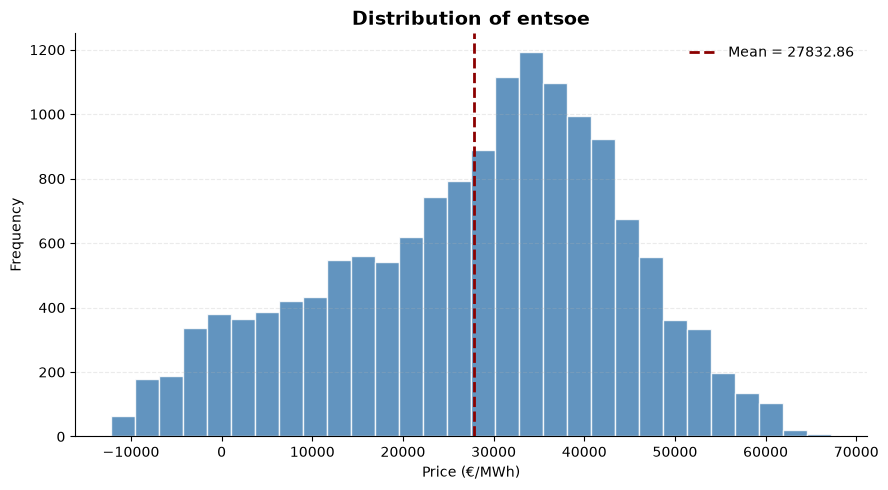

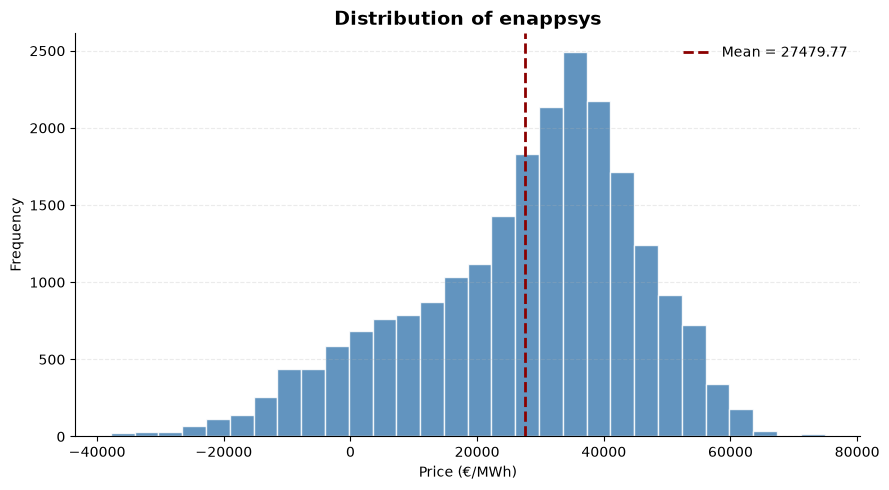

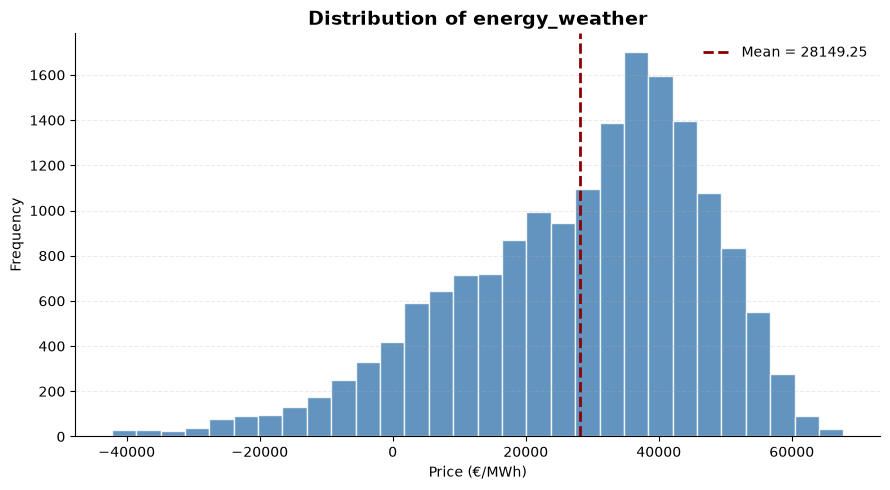

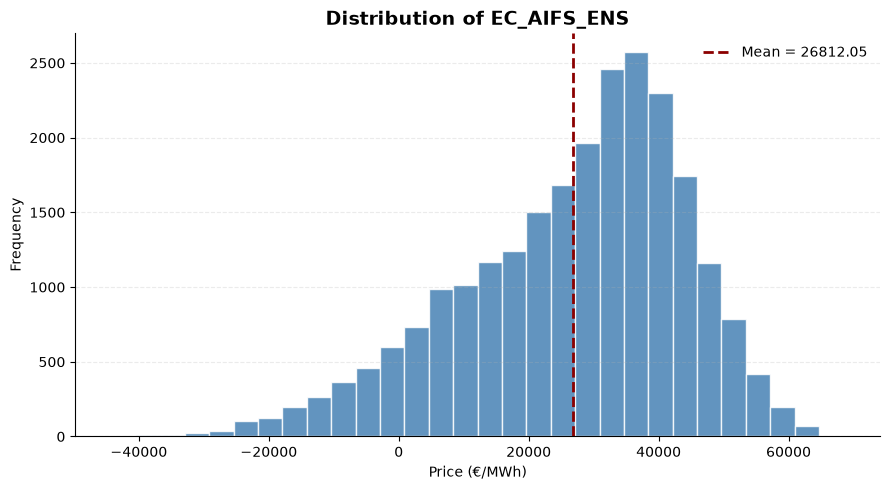

In [ ]:
import matplotlib.pyplot as plt

providers = ["entsoe", "enappsys", "energy_weather","EC_AIFS_ENS"]

for col in providers:
    data = result[col].drop_nulls().to_numpy()
    mean = data.mean()

    plt.figure(figsize=(9, 5))

    plt.hist(
        data,
        bins=30,
        color="steelblue",
        edgecolor="white",
        alpha=0.85
    )

    # Mean line
    plt.axvline(
        mean,
        color="darkred",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean:.2f}"
    )

    plt.title(
        f"Distribution of {col}",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Price (€/MWh)")
    plt.ylabel("Frequency")

    plt.grid(axis="y", alpha=0.25, linestyle="--")
    plt.legend(frameon=False)

    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()